# 08 · 바이오 프로세스 데이터 탐색과 생산량 예측
### 실습으로 배우는 GMP AI — 강의 목차 ⑨ 바이오 프로세스 데이터 탐색과 생산량 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/08_Bioprocess_Data_Yield_Prediction.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 발효 공정 데이터의 구조(배치 궤적) ② **정상 vs 고장 배치** 패턴 비교 ③ 제어 전략(레시피·작업자·PAT)별 성능 ④ 배치 요약 특성 + PCA 로 **골든 배치** 찾기 ⑤ 최종 생산량 예측·고장 배치 분류 |
| **데이터** | **IndPenSim** — 10만 리터 산업용 페니실린 발효 시뮬레이터, **100 배치 · 113,935 측정점 · 37 변수** (Goldrick et al., 공개 벤치마크) |
| **실행 환경** | CPU · 약 10분 (데이터 19MB 다운로드) |

> 화학 합성과 달리 **생물 공정은 살아있는 세포**가 만듭니다. 비선형적이고 배치마다 다르며,
> 핵심 품질(역가)은 **실시간 측정이 어렵습니다** → AI 의 가치가 큰 영역입니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import warnings; warnings.filterwarnings("ignore")
URL = "https://raw.githubusercontent.com/StillWork/data/refs/heads/master/100_Batches_IndPenSim_V3_no_raman.csv"
t = time.time()
df = pd.read_csv(URL)
df.columns = [c.split("(")[0].strip() for c in df.columns]      # 긴 열 이름 정리
print(f"데이터: {df.shape[0]:,}행 × {df.shape[1]}열  ({time.time()-t:.0f}초)")
print("배치 수:", df["Batch ID"].nunique())
df[["Time", "Batch ID", "Penicillin concentration", "Dissolved oxygen concentration", "pH", "Temperature"]].head(3)

Note: you may need to restart the kernel to use updated packages.


데이터: 113,935행 × 37열  (1초)
배치 수: 100


,Time,Batch ID,Penicillin concentration,Dissolved oxygen concentration,pH,Temperature
0,0.2,1,1.017800e-25,14.711,6.4472,298.22
1,0.4,1,1.000000e-03,14.699,6.4932,298.17
2,0.6,1,9.993400e-04,14.686,6.5425,298.14


## 1. IndPenSim 데이터 구조
**상류 공정(Upstream)** 인 페니실린 발효를 모사한 공개 벤치마크입니다 (실제 산업 설비 기반).

| 구분 | 변수 | GMP 용어 |
|---|---|---|
| **조작 변수 (입력)** | 교반 속도, 통기량, 당 공급 속도, 산/염기 유량, 냉각수 유량, PAA 유량 | **CPP** |
| **상태 변수 (온라인 센서)** | pH, 온도, 용존산소(DO), 배기가스 CO₂·O₂, 발열량, 부피·중량 | 실시간 측정 |
| **품질 변수 (오프라인)** | **페니실린 농도(P)**, 균체 농도(X), 기질 농도(S), 점도 | **CQA** (분석실 시험) |
| **운전 조건** | 제어 방식(레시피/작업자/PAT), 고장 플래그 | 배치 메타데이터 |

| 배치 번호 | 제어 방식 |
|---|---|
| 1–30 | **레시피 기반** 자동 제어 |
| 31–60 | **작업자** 수동 제어 |
| 61–90 | **PAT 기반 고급 제어** (라만 분광 활용) |
| 91–100 | **고장 포함 배치** (공정 일탈) |

In [2]:
meta = df.groupby("Batch ID").agg(
    길이_h=("Time", "max"), 샘플수=("Time", "size"),
    최종_페니실린=("Penicillin concentration", "max"),
    최종_균체=("Offline Biomass concentratio", "max"),
    고장=("Fault flag", "max"), 작업자제어=("0 - Recipe driven 1 - Operator controlled", "max"),
    PAT=("2-PAT control", "max"))
def ctrl_name(r):
    if r["고장"] == 1: return "고장 배치"
    if r["PAT"] == 2: return "PAT 제어"
    if r["작업자제어"] == 1: return "작업자 제어"
    return "레시피 제어"
meta["제어방식"] = meta.apply(ctrl_name, axis=1)
print(meta["제어방식"].value_counts().to_string())
print(f"\n배치 길이: {meta.길이_h.min():.0f}~{meta.길이_h.max():.0f} 시간 (샘플 간격 0.2h)")
meta.groupby("제어방식")[["최종_페니실린", "최종_균체", "길이_h"]].agg(["mean", "std", "min", "max"]).round(2)

제어방식
레시피 제어    30
작업자 제어    30
PAT 제어    30
고장 배치     10

배치 길이: 167~290 시간 (샘플 간격 0.2h)


최종_페니실린                      최종_균체                        길이_h         \
          mean   std    min    max   mean   std    min    max    mean    std   
제어방식                                                                           
PAT 제어   29.42  2.71  21.60  33.21  24.95  1.33  22.46  27.19  224.67  15.35   
고장 배치    19.82  9.12   8.42  32.81  23.00  2.75  18.30  25.96  230.50  14.94   
레시피 제어   27.56  5.10  15.10  36.18  24.90  1.33  22.52  27.25  228.83  24.30   
작업자 제어   26.31  5.21  13.78  35.09  24.96  1.54  21.40  27.88  229.23  14.61   

                      
          min    max  
제어방식                  
PAT 제어  167.0  241.0  
고장 배치   210.0  258.0  
레시피 제어  179.0  290.0  
작업자 제어  193.0  262.0

## 2. 배치 궤적(trajectory) — 발효의 4단계
| 단계 | 시간 | 특징 |
|---|---|---|
| **지체기(lag)** | 0~20h | 균이 환경에 적응, 성장 거의 없음 |
| **대수성장기(exponential)** | 20~45h | 균체 급증, 산소 소비 급증, 페니실린은 아직 적음 |
| **생산기(production)** | 45~200h | 성장 억제·**2차 대사산물인 페니실린 생산** |
| **쇠퇴기(decline)** | 200h~ | 균 사멸, 점도 상승, 생산성 저하 |

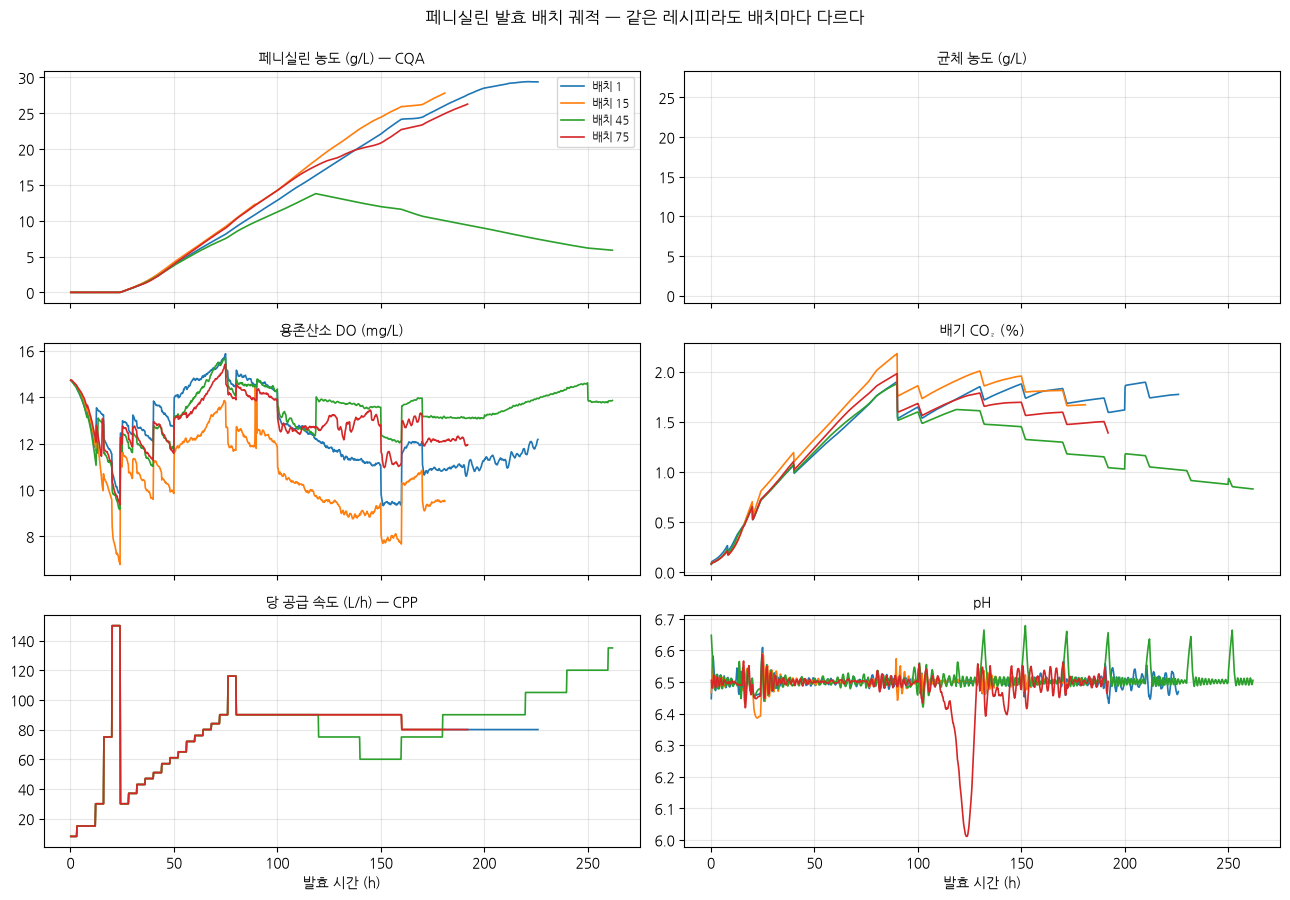

In [3]:
sample_batches = [1, 15, 45, 75]
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
plots = [("Penicillin concentration", "페니실린 농도 (g/L) — CQA"), ("Offline Biomass concentratio", "균체 농도 (g/L)"),
         ("Dissolved oxygen concentration", "용존산소 DO (mg/L)"), ("carbon dioxide percent in off-gas", "배기 CO₂ (%)"),
         ("Sugar feed rate", "당 공급 속도 (L/h) — CPP"), ("pH", "pH")]
for a, (col, title) in zip(ax.ravel(), plots):
    for b in sample_batches:
        g = df[df["Batch ID"] == b]
        a.plot(g["Time"], g[col], lw=1.2, label=f"배치 {b}")
    a.set_title(title, fontsize=10); a.grid(alpha=0.3)
ax[0, 0].legend(fontsize=8); ax[-1, 0].set_xlabel("발효 시간 (h)"); ax[-1, 1].set_xlabel("발효 시간 (h)")
plt.suptitle("페니실린 발효 배치 궤적 — 같은 레시피라도 배치마다 다르다", y=0.995); plt.tight_layout(); plt.show()

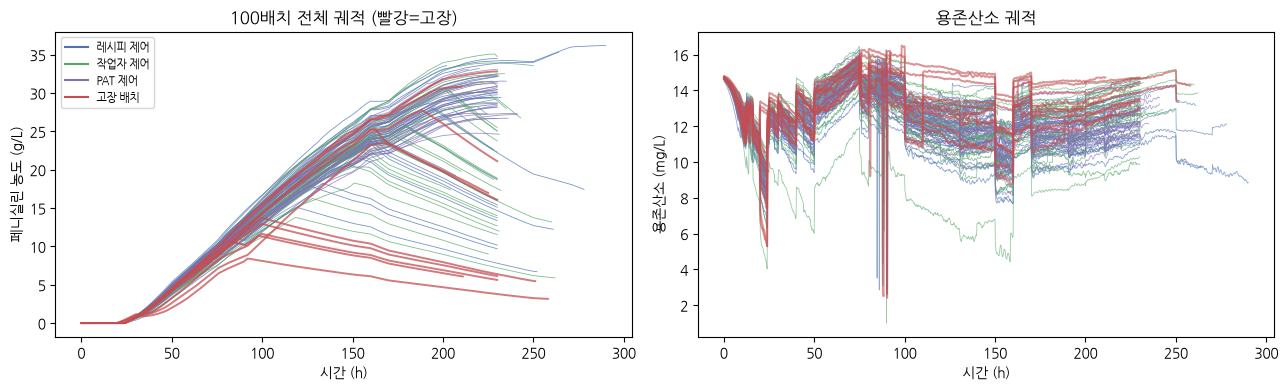

In [4]:
# 모든 배치를 겹쳐 보기 — '정상 범위'와 벗어난 배치를 눈으로 확인
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = {"레시피 제어": "#4C72B0", "작업자 제어": "#55A868", "PAT 제어": "#8172B3", "고장 배치": "#C44E52"}
for b in meta.index:
    g = df[df["Batch ID"] == b]
    c = colors[meta.loc[b, "제어방식"]]
    lw = 1.4 if meta.loc[b, "제어방식"] == "고장 배치" else 0.6
    ax[0].plot(g["Time"], g["Penicillin concentration"], color=c, lw=lw, alpha=0.75)
    ax[1].plot(g["Time"], g["Dissolved oxygen concentration"], color=c, lw=lw, alpha=0.6)
for k, c in colors.items(): ax[0].plot([], [], color=c, label=k)
ax[0].legend(fontsize=8); ax[0].set_xlabel("시간 (h)"); ax[0].set_ylabel("페니실린 농도 (g/L)"); ax[0].set_title("100배치 전체 궤적 (빨강=고장)")
ax[1].set_xlabel("시간 (h)"); ax[1].set_ylabel("용존산소 (mg/L)"); ax[1].set_title("용존산소 궤적")
plt.tight_layout(); plt.show()

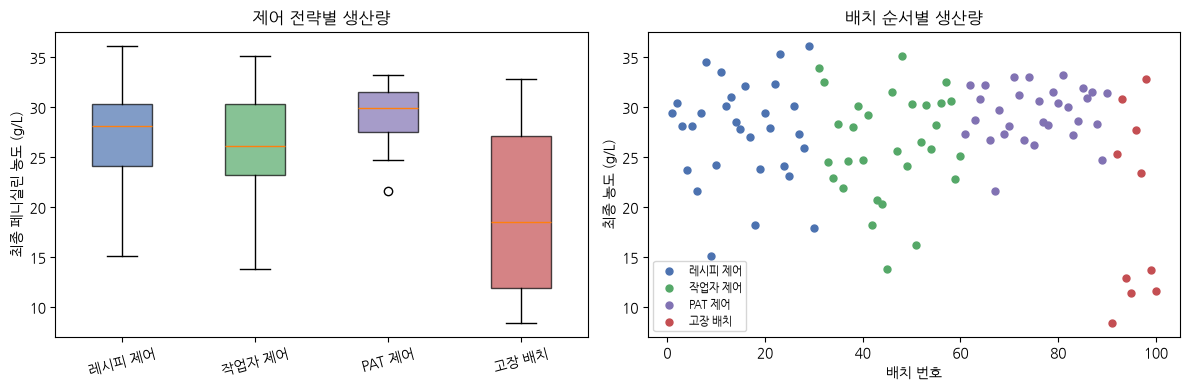

,mean,std,count
제어방식,,,
PAT 제어,29.42,2.71,30
고장 배치,19.82,9.12,10
레시피 제어,27.56,5.10,30
작업자 제어,26.31,5.21,30


→ 변동(std)이 작을수록 공정이 재현성 있게 관리되고 있다는 뜻입니다 (QbD 의 목표).


In [5]:
# 제어 전략별 최종 수율 — PAT 기반 제어의 효과
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = ["레시피 제어", "작업자 제어", "PAT 제어", "고장 배치"]
data_box = [meta[meta.제어방식 == k]["최종_페니실린"].values for k in order]
bp = ax[0].boxplot(data_box, patch_artist=True)
ax[0].set_xticks(range(1, len(order) + 1)); ax[0].set_xticklabels(order)
for p, k in zip(bp["boxes"], order): p.set_facecolor(colors[k]); p.set_alpha(0.7)
ax[0].set_ylabel("최종 페니실린 농도 (g/L)"); ax[0].set_title("제어 전략별 생산량"); ax[0].tick_params(axis="x", rotation=15)
for k in order:
    m = meta[meta.제어방식 == k]
    ax[1].scatter(m.index, m["최종_페니실린"], color=colors[k], label=k, s=25)
ax[1].set_xlabel("배치 번호"); ax[1].set_ylabel("최종 농도 (g/L)"); ax[1].legend(fontsize=8); ax[1].set_title("배치 순서별 생산량")
plt.tight_layout(); plt.show()
display(meta.groupby("제어방식")["최종_페니실린"].agg(["mean", "std", "count"]).round(2))
print("→ 변동(std)이 작을수록 공정이 재현성 있게 관리되고 있다는 뜻입니다 (QbD 의 목표).")

## 3. 배치 요약 특성 만들기 — 궤적을 숫자로
배치마다 길이가 달라도 비교할 수 있도록 **단계별 요약 통계**를 만듭니다 (예제 04와 같은 전략).

In [6]:
ONLINE = ["Aeration rate", "Agitator RPM", "Sugar feed rate", "Acid flow rate", "Base flow rate",
          "Heating/cooling water flow rate", "Water for injection/dilution", "Air head pressure",
          "Dissolved oxygen concentration", "Vessel Volume", "Vessel Weight", "pH", "Temperature",
          "Generated heat", "carbon dioxide percent in off-gas", "PAA flow", "Oil flow",
          "Oxygen Uptake Rate", "Oxygen in percent in off-gas", "Carbon evolution rate"]
PHASES = {"초기(0-50h)": (0, 50), "중기(50-150h)": (50, 150), "후기(150h-)": (150, 1e9)}

def summarize(g):
    f = {"길이_h": g["Time"].max()}
    for pname, (lo, hi) in PHASES.items():
        sub = g[(g["Time"] >= lo) & (g["Time"] < hi)]
        if len(sub) < 5: continue
        for c in ONLINE:
            f[f"{c}|{pname}|평균"] = sub[c].mean()
            f[f"{c}|{pname}|표준편차"] = sub[c].std()
    return f

t = time.time()
feat = pd.DataFrame({b: summarize(g) for b, g in df.groupby("Batch ID")}).T
feat = feat.fillna(feat.median())
print(f"배치 요약 특성: {feat.shape} ({time.time()-t:.0f}초)")
feat.iloc[:3, :5].round(2)

배치 요약 특성: (100, 121) (0초)


,길이_h,Aeration rate|초기(0-50h)|평균,Aeration rate|초기(0-50h)|표준편차,Agitator RPM|초기(0-50h)|평균,Agitator RPM|초기(0-50h)|표준편차
1,226.0,48.84,10.42,100.0,0.0
2,230.0,48.84,10.42,100.0,0.0
3,278.0,48.84,10.42,100.0,0.0


## 4. PCA — 배치 지문(fingerprint)과 골든 배치
배치별 요약 특성을 2차원으로 압축하면 **어떤 배치가 서로 비슷한지** 한눈에 보입니다.
**골든 배치(Golden Batch)** = 품질·수율이 가장 좋았던 기준 배치. 신규 배치가 골든 배치 궤적에서 얼마나 벗어나는지 감시하는 것이 바이오 공정 모니터링의 기본입니다.

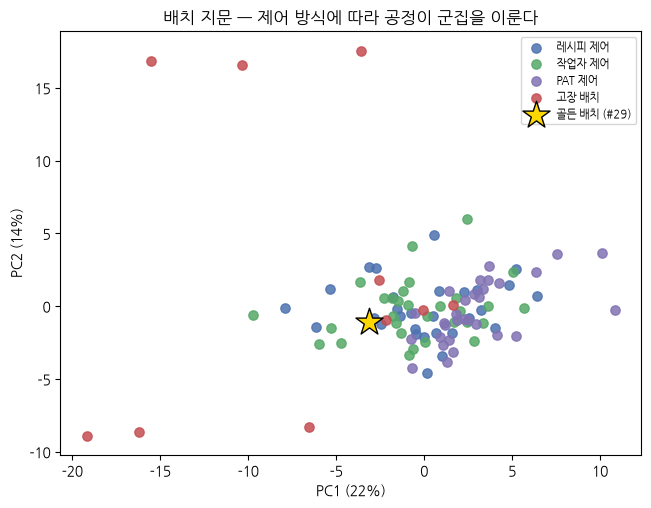

골든 배치 #29: 최종 36.2 g/L


In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(feat)
pca = PCA(2).fit(Z); P = pca.transform(Z)
plt.figure(figsize=(7.5, 5.5))
for k in order:
    m = meta[meta.제어방식 == k].index
    ii = [feat.index.get_loc(b) for b in m if b in feat.index]
    plt.scatter(P[ii, 0], P[ii, 1], color=colors[k], label=k, s=45, alpha=0.85)
golden = meta[meta.고장 == 0]["최종_페니실린"].idxmax()
gi = feat.index.get_loc(golden)
plt.scatter(P[gi, 0], P[gi, 1], marker="*", s=420, color="gold", edgecolor="k", label=f"골든 배치 (#{golden})", zorder=5)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.legend(fontsize=8); plt.title("배치 지문 — 제어 방식에 따라 공정이 군집을 이룬다"); plt.show()
print(f"골든 배치 #{golden}: 최종 {meta.loc[golden,'최종_페니실린']:.1f} g/L")

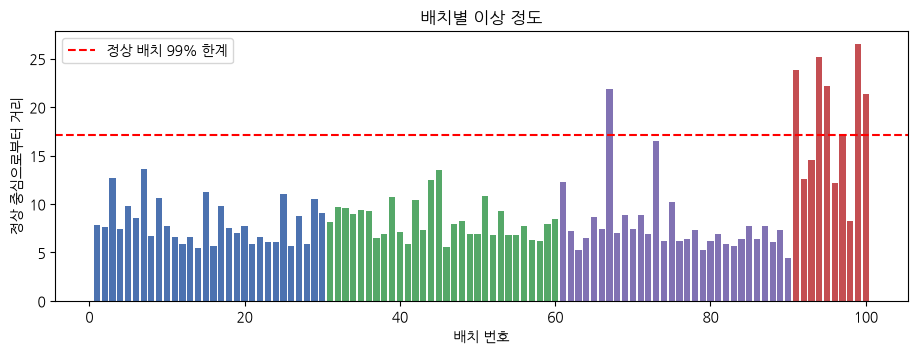

고장 배치 10개 중 6개를 이 단순 거리 지표만으로 탐지 (탐지율 60%)


In [8]:
# 골든 배치와의 거리로 '정상에서 벗어난 정도' 측정 (예제 06의 이상탐지와 같은 아이디어)
normal_idx = [feat.index.get_loc(b) for b in meta[meta.고장 == 0].index]
center = Z[normal_idx].mean(0)
dist = np.linalg.norm(Z - center, axis=1)
meta["중심거리"] = dist
plt.figure(figsize=(11, 3.5))
plt.bar(meta.index, meta["중심거리"], color=[colors[k] for k in meta["제어방식"]])
lim = np.percentile(meta.loc[meta.고장 == 0, "중심거리"], 99)
plt.axhline(lim, color="red", ls="--", label="정상 배치 99% 한계")
plt.xlabel("배치 번호"); plt.ylabel("정상 중심으로부터 거리"); plt.legend(); plt.title("배치별 이상 정도"); plt.show()
det = (meta.loc[meta.고장 == 1, "중심거리"] > lim).mean()
print(f"고장 배치 10개 중 {int(det*10)}개를 이 단순 거리 지표만으로 탐지 (탐지율 {det:.0%})")

## 5. 최종 생산량 예측 — 배치가 끝나기 전에 알 수 있을까
배치의 **앞부분 데이터만** 사용해 최종 수율을 예측합니다. 평가는 **배치 단위 교차검증**(한 배치의 데이터가 학습·평가에 섞이지 않도록)으로 합니다.

,사용한 배치 진행률,R2,MAE (g/L)
0,20%,0.041,4.274
1,40%,0.186,3.918
2,60%,0.487,3.242
3,80%,0.727,2.398
4,100%,0.748,2.218


(5초)


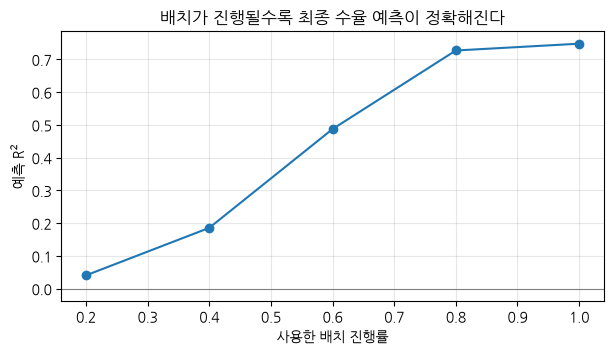

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score, mean_absolute_error

final_P = meta["최종_페니실린"]
def partial_features(frac):
    rows = {}
    for b, g in df.groupby("Batch ID"):
        g = g.sort_values("Time"); sub = g.iloc[:int(len(g) * frac)]
        f = {}
        for c in ONLINE:
            f[f"{c}_평균"] = sub[c].mean(); f[f"{c}_마지막"] = sub[c].iloc[-1]
            f[f"{c}_기울기"] = np.polyfit(np.arange(len(sub)), sub[c].values, 1)[0]
        rows[b] = f
    return pd.DataFrame(rows).T

t = time.time(); rows = []
for frac in [0.2, 0.4, 0.6, 0.8, 1.0]:
    X = partial_features(frac)
    pred = cross_val_predict(RandomForestRegressor(300, n_jobs=-1, random_state=0), X, final_P.loc[X.index],
                             cv=KFold(5, shuffle=True, random_state=0))
    rows.append({"사용한 배치 진행률": f"{frac:.0%}", "R2": r2_score(final_P.loc[X.index], pred),
                 "MAE (g/L)": mean_absolute_error(final_P.loc[X.index], pred)})
res = pd.DataFrame(rows)
display(res.round(3))
print(f"({time.time()-t:.0f}초)")
plt.figure(figsize=(7, 3.5))
plt.plot([0.2, 0.4, 0.6, 0.8, 1.0], res["R2"], "o-")
plt.axhline(0, color="gray", lw=0.8); plt.xlabel("사용한 배치 진행률"); plt.ylabel("예측 R$^2$")
plt.title("배치가 진행될수록 최종 수율 예측이 정확해진다"); plt.grid(alpha=0.3); plt.show()

> **해석**: 초반 20~40% 데이터만으로는 최종 수율을 거의 예측하지 못합니다(R² ≈ 0).
> 생물 공정의 결과는 **생산기 이후의 거동**에 크게 좌우되기 때문입니다.
> → 이 곡선이 바로 **RTRT(실시간 출하시험) 적용 시점**을 정하는 근거가 됩니다 (예제 09에서 자세히).

## 6. 고장 배치 분류 — 공정 일탈 자동 판정

고장 배치 분류 ROC-AUC = 0.812  (고장 10건 / 100배치)
              precision    recall  f1-score   support

          정상      0.923     0.933     0.928        90
          고장      0.333     0.300     0.316        10

    accuracy                          0.870       100
   macro avg      0.628     0.617     0.622       100
weighted avg      0.864     0.870     0.867       100



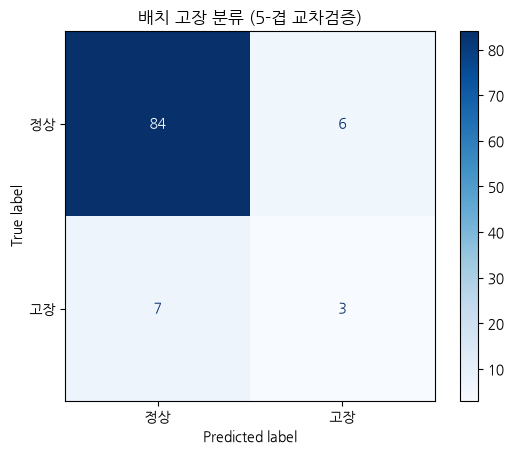

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

X_full = partial_features(1.0)
y_fault = meta.loc[X_full.index, "고장"].values
proba = cross_val_predict(RandomForestClassifier(500, n_jobs=-1, random_state=0, class_weight="balanced"),
                          X_full, y_fault, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print(f"고장 배치 분류 ROC-AUC = {roc_auc_score(y_fault, proba):.3f}  (고장 {y_fault.sum()}건 / {len(y_fault)}배치)")
print(classification_report(y_fault, (proba >= 0.5).astype(int), target_names=["정상", "고장"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_fault, (proba >= 0.5).astype(int)), display_labels=["정상", "고장"]).plot(cmap="Blues")
plt.title("배치 고장 분류 (5-겹 교차검증)"); plt.show()

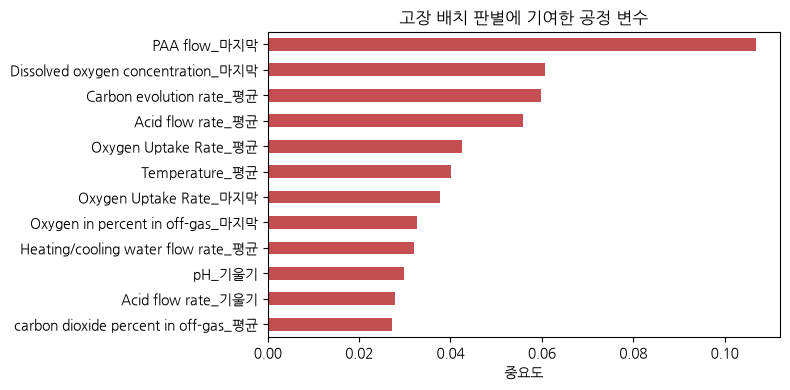

In [11]:
# 어떤 변수가 고장을 알려주나
clf = RandomForestClassifier(500, n_jobs=-1, random_state=0, class_weight="balanced").fit(X_full, y_fault)
imp = pd.Series(clf.feature_importances_, index=X_full.columns).sort_values().tail(12)
imp.plot.barh(figsize=(8, 4), color="#C44E52"); plt.xlabel("중요도"); plt.title("고장 배치 판별에 기여한 공정 변수"); plt.tight_layout(); plt.show()

## 🧪 LLM 코딩 과제
```
df(IndPenSim, 열: 'Batch ID','Time','Penicillin concentration','pH','Temperature','Dissolved oxygen concentration')가 있어.
정상 배치(1~90)의 pH 궤적 평균과 ±3 표준편차 범위를 시간대별로 계산해서 '골든 배치 밴드'를 그리고,
고장 배치(91~100) 궤적을 그 위에 겹쳐 그려줘. 밴드를 벗어나는 시점도 표시해줘. 한글 주석을 달아줘.
```

In [12]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 배치 궤적 | 생물 공정은 배치마다 다르다 — **궤적 전체**를 봐야 한다 |
| 제어 전략 | PAT 기반 제어는 **평균보다 변동(재현성)** 에서 차이를 만든다 |
| 배치 요약 특성 | 단계별 통계로 길이가 다른 배치를 비교 가능하게 |
| 골든 배치 | 기준 배치·정상 중심에서의 거리로 이상 감시 |
| 수율 예측 | 배치 초반에는 예측 불가 → **진행률별 신뢰도 곡선**이 RTRT 설계의 근거 |

➡️ **다음 예제 09**: 측정하기 어려운 품질을 실시간 추정하는 **소프트센서와 PAT·RTRT**